# Table of contents
* [Load the data](#loaddata)
* [Analyze and clean the data](#analyze-clean)
* [Classical Machine Learning](#classical)
  * [Convert Text Documents to a TF-IDF Matrix](#TF-IDF)
  * [Split the data into train and test](#split)
  * [Over- and undersampling the data](#over-under)
  * [Train the model](#train)
    * [Logistic Regression](#logistic)
    * [Multinomial Naive Bayes](#nb)
    * [Support Vector Machines](#svm)
    * [Random Forest](#rf)
* [BERT-Mini](#bert)
  * [Transform to HuggingFace dataset](#hfdata)
  * [Tokenizer](#tokenizer)
  * [Metrics](#metrics)
  * [Training](#training)
  * [Explainability using SHAP](#shap)
  * [Inference](#inference)
* [Conclusion](#conclusion)


In [ ]:
!pip install numpy pandas nltk matplotlib ipywidgets scikit-learn imbalanced-learn torch transformers datasets evaluate accelerate shap

# Load the data <a name="loaddata"></a>

In [8]:
import os
import pandas as pd

cwd = os.getcwd()
dataset = f"{cwd}/file.txt"
#dataset = "/kaggle/input/document-classification/file.txt"
print(f"Dataset found = {os.path.exists(dataset)}")

df = pd.read_csv(dataset)
df

Dataset found = True


,5485
0,1 champion products ch approves stock split ch...
1,2 computer terminal systems cpml completes sal...
2,1 cobanco inc cbco year net shr cts vs dlrs ne...
3,1 am international inc am nd qtr jan oper shr ...
4,1 brown forman inc bfd th qtr net shr one dlr ...
...,...
5480,1 kelly oil and gas partners kly year dec shr ...
5481,8 japan seeks to strengthen paris currency acc...
5482,1 tcw convertible securities cvt sets dividend...
5483,8 south korean won fixed at month high the ban...


# Analyze and clean the data <a name="analyze-clean"></a>


In [9]:
# Create the columns for documents and labels

labels = []
for i in df['5485']:
    labels.append(int(i[0]))

df['label'] = labels
df = df.rename({'5485':'document'}, axis=1)
df['document'] = df['document'].str[1:]
df.head(5)

,document,label
0,champion products ch approves stock split cha...,1
1,computer terminal systems cpml completes sale...,2
2,cobanco inc cbco year net shr cts vs dlrs net...,1
3,am international inc am nd qtr jan oper shr l...,1
4,brown forman inc bfd th qtr net shr one dlr v...,1


In [10]:
# Any empty rows

df.isnull().sum()

document    0
label       0
dtype: int64

In [11]:
# Clean the documents

import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
nltk.download('punkt')
nltk.download('stopwords')

def clean(document):
    # remove newlines
    document = document.replace('\n', '')
    # lowercase
    document = document.lower()
    # remove special characters
    punctuation_pattern = r'[^\w\s]'
    document = re.sub(punctuation_pattern, '', document)
    # remove stopwords
    new_words = word_tokenize(document)
    new_filtered_words = [word for word in new_words if word not in stopwords.words('english')]
    document = ' '.join(new_filtered_words)
    # remove urls
    url_pattern = re.compile(r'https?://\S+|www\.\S+')
    document = url_pattern.sub(r'', document)
    # remove html tags
    html_tags_pattern = r'<.*?>'
    document = re.sub(html_tags_pattern, '', document)
    return document

df['document'] = df['document'].apply(clean)
df.head(5)

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,document,label
0,champion products ch approves stock split cham...,1
1,computer terminal systems cpml completes sale ...,2
2,cobanco inc cbco year net shr cts vs dlrs net ...,1
3,international inc nd qtr jan oper shr loss two...,1
4,brown forman inc bfd th qtr net shr one dlr vs...,1


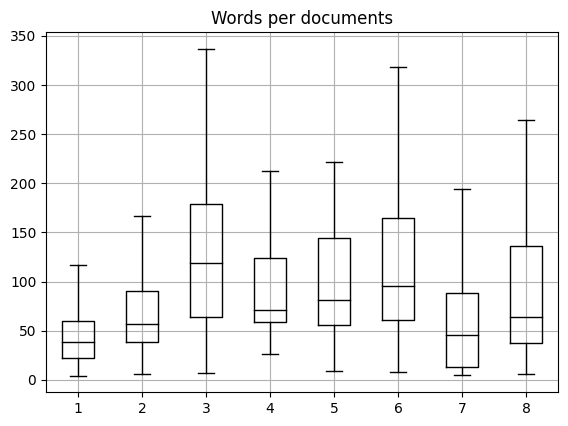

In [12]:
# Words per documents

import matplotlib.pyplot as plt

df['Words per documents'] = df['document'].str.split().apply(len)
df.boxplot('Words per documents', by='label', grid=True, showfliers=False, color='black')
plt.suptitle('')
plt.xlabel('')
plt.show()

In [13]:
# Documents longer than 512

df[(df[['Words per documents']]>512).all(axis=1)]

,document,label,Words per documents
1977,g round one goes central banks central banks e...,8,530
2901,economic spotlight u deficit nics u trade defi...,3,555


In [14]:
# Percentage of documents shorter than 100

len(df[(df[['Words per documents']]<100).all(axis=1)]) / len(df)

0.8012762078395624

In [15]:
# Shortest document

shortest_document = min(df['document'], key=len)
shortest_document

'gencorp st qtr shr cts vs cts'

After cleaning the data, most of the documents have less than 512 words. This is important for using Mini-BERT later which has a tokenizer with max_length=512. There is only 2 documents with a bit over 512 words, therefore let's not do any modifications now, and let the Mini-BERT tokenizer truncate those documents to 512.

Moreover, 80% of all documents have less than 100 words. Therefore, documents are on the shorter side, with the shortest consisting of 7 words. It is also important to note that class 1 has especially short documents.

In [16]:
print(f"Number of rows in the dataset = {df.shape[0]} \n")

num_labels = df['label'].nunique()
print(f"Number of unique labels = {num_labels} \n")

# Distribution by labels
df['label'].value_counts()

Number of rows in the dataset = 5485 

Number of unique labels = 8 



label
1    2840
2    1596
6     253
3     251
8     206
7     190
4     108
5      41
Name: count, dtype: int64

The dataset is class imbalanced, with classes 5 and 4 having significantly less data points than classes 1 and 2!

Therefore, we will:
- upsample the data in the minority classes, and downsample the data in the majority classes for classical machine learning methods,
- split the data in a stratified manner, and
- make sure to use precision and recall as metrics as well.

# Classical Machine Learning <a name="classical"></a>

Before we can apply over- and undersampling methods, we need to tokenize the documents, and split the dataset into train and test.

## Convert Text Documents to a TF-IDF Matrix <a name="TF-IDF"></a>

We will use TF-IDF, which is the product of term frequency and inverse document frequency. It gives more importance to the word that is rare in the corpus and common in a document. We choose this method because it takes both term frequency and document frequency into account.

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X, y = df['document'].to_numpy(), df['label']

X_vectorized = vectorizer.fit_transform(X)

X_vectorized

<5485x19821 sparse matrix of type '<class 'numpy.float64'>'
	with 252251 stored elements in Compressed Sparse Row format>

## Split the data into train and test <a name="split"></a>

In [18]:
# Split the data in a stratified manner

from sklearn.model_selection import train_test_split

test_split = 0.2
X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized, y, test_size=test_split, random_state=42, stratify=y.values
)

print(f"Number of rows in training set: {y_train.shape[0]} \n")
print(f"Number of rows in test set: {y_test.shape[0]}")

Number of rows in training set: 4388 

Number of rows in test set: 1097


## Over- and undersampling the data <a name="over-under"></a>

In [19]:
# Distribution by labels in the training set
y_train.value_counts()

label
1    2272
2    1277
6     202
3     201
8     165
7     152
4      86
5      33
Name: count, dtype: int64

In [20]:
# Upsample the data in classes 5 and 4 to 150 instances
# Downsample the data in classes 1 and 2 to 250 instances

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import ClusterCentroids
from imblearn.pipeline import Pipeline
import time

# ClusterCentroids can be computationally intensive, let's make sure we keep track of this using a timer
start = time.time()

over= SMOTE(sampling_strategy = {5:150, 4:150})
under= ClusterCentroids(sampling_strategy = {1:250, 2:250})
steps = [('o', over), ('u', under)]
pipeline = Pipeline(steps=steps)

X_train_resampled, y_train_resampled = pipeline.fit_resample(X_train, y_train)

end = time.time()
elapsed_time = end - start
print(f"Time elapsed for over- and undersampling = {elapsed_time:.2f}s \n")

# Distribution by labels
print(y_train_resampled.value_counts())

print(f"\n Number of rows in the training dataset = {y_train_resampled.shape[0]}")

/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Time elapsed for over- and undersampling = 48.12s 

label
1    250
2    250
6    202
3    201
8    165
7    152
4    150
5    150
Name: count, dtype: int64

 Number of rows in the training dataset = 1520


## Train the model <a name="train"></a>

In [21]:
# Training and testing function

from sklearn.metrics import classification_report

def train_and_test(classifier, X, y, X_test, y_test):
    classifier.fit(X, y)
    y_pred = classifier.predict(X_test)
    print(classification_report(y_test, y_pred))

### Logistic Regression <a name="logistic"></a>

In [22]:
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression()

# without over- and undersampling
print(f"Logistic regression without over- and undersampling \n")
train_and_test(classifier, X_train, y_train, X_test, y_test)

# with over- and undersampling
print(f"\n Logistic regression with over- and undersampling \n")
train_and_test(classifier, X_train_resampled, y_train_resampled, X_test, y_test)

Logistic regression without over- and undersampling 

              precision    recall  f1-score   support

           1       0.99      0.97      0.98       568
           2       0.86      1.00      0.93       319
           3       0.96      0.96      0.96        50
           4       1.00      0.45      0.62        22
           5       1.00      0.25      0.40         8
           6       1.00      0.84      0.91        51
           7       0.97      0.79      0.87        38
           8       0.94      0.80      0.87        41

    accuracy                           0.95      1097
   macro avg       0.97      0.76      0.82      1097
weighted avg       0.95      0.95      0.94      1097


 Logistic regression with over- and undersampling 

              precision    recall  f1-score   support

           1       1.00      0.95      0.97       568
           2       0.90      0.99      0.94       319
           3       0.98      1.00      0.99        50
           4       1.00  

Without over- and undersampling recall is bad for the minority classes 4 and 5. With over- and undersampling recall improves for those classes, and gives overall satisfiying results. Moreover, accuracy didn't change much in both cases, which says that it's important to take precision and recall into consideration as well.

### Multinomial Naive Bayes <a name="nb"></a>

In [23]:
from sklearn.naive_bayes import MultinomialNB

classifier = MultinomialNB()

# without over- and undersampling
print(f"Multinomial Naive Bayes without over- and undersampling \n")
train_and_test(classifier, X_train, y_train, X_test, y_test)

# with over- and undersampling
print(f"\n Multinomial Naive Bayes with over- and undersampling \n")
train_and_test(classifier, X_train_resampled, y_train_resampled, X_test, y_test)

Multinomial Naive Bayes without over- and undersampling 

              precision    recall  f1-score   support

           1       0.89      0.98      0.93       568
           2       0.76      0.97      0.85       319
           3       0.92      0.48      0.63        50
           4       0.00      0.00      0.00        22
           5       0.00      0.00      0.00         8
           6       1.00      0.29      0.45        51
           7       1.00      0.11      0.19        38
           8       1.00      0.32      0.48        41

    accuracy                           0.84      1097
   macro avg       0.70      0.39      0.44      1097
weighted avg       0.84      0.84      0.81      1097


 Multinomial Naive Bayes with over- and undersampling 

              precision    recall  f1-score   support

           1       0.99      0.98      0.98       568
           2       0.96      0.98      0.97       319
           3       0.72      1.00      0.84        50
           4     

/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Without over- and undersampling minority classes don't get predicted at all. With over- and undersampling f1-score improves, but is overall worse than for logistic regression.

### Support Vector Machines <a name="svm"></a>

In [24]:
from sklearn import svm

classifier = svm.SVC()

# without over- and undersampling
print(f"SVM without over- and undersampling \n")
train_and_test(classifier, X_train, y_train, X_test, y_test)

# with over- and undersampling
print(f"\n SVM with over- and undersampling \n")
train_and_test(classifier, X_train_resampled, y_train_resampled, X_test, y_test)

SVM without over- and undersampling 

              precision    recall  f1-score   support

           1       1.00      0.97      0.99       568
           2       0.85      1.00      0.92       319
           3       0.98      0.96      0.97        50
           4       1.00      0.41      0.58        22
           5       1.00      0.25      0.40         8
           6       1.00      0.86      0.93        51
           7       0.97      0.79      0.87        38
           8       0.92      0.80      0.86        41

    accuracy                           0.95      1097
   macro avg       0.96      0.76      0.81      1097
weighted avg       0.95      0.95      0.94      1097


 SVM with over- and undersampling 

              precision    recall  f1-score   support

           1       1.00      0.93      0.96       568
           2       0.85      1.00      0.92       319
           3       0.96      0.98      0.97        50
           4       1.00      0.82      0.90        22
   

### Random Forest <a name="rf"></a>

In [25]:
from sklearn.ensemble import RandomForestClassifier

classifier = RandomForestClassifier()

# without over- and undersampling
print(f"Random Forest without over- and undersampling \n")
train_and_test(classifier, X_train, y_train, X_test, y_test)

# with over- and undersampling
print(f"\n Random Forest with over- and undersampling \n")
train_and_test(classifier, X_train_resampled, y_train_resampled, X_test, y_test)

Random Forest without over- and undersampling 



/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


              precision    recall  f1-score   support

           1       0.99      0.96      0.98       568
           2       0.85      1.00      0.92       319
           3       0.87      0.96      0.91        50
           4       1.00      0.59      0.74        22
           5       0.00      0.00      0.00         8
           6       1.00      0.76      0.87        51
           7       0.97      0.74      0.84        38
           8       0.86      0.73      0.79        41

    accuracy                           0.93      1097
   macro avg       0.82      0.72      0.76      1097
weighted avg       0.93      0.93      0.93      1097


 Random Forest with over- and undersampling 

              precision    recall  f1-score   support

           1       1.00      0.94      0.97       568
           2       0.89      0.97      0.93       319
           3       0.89      1.00      0.94        50
           4       1.00      0.86      0.93        22
           5       1.00      0.

Logistic regression performed the best out of the four used models.

# BERT-Mini <a name="bert"></a>

BERT is a state-of-the-art model for many NLP tasks, including text classification. It leverages transformer architecture to achieve high accuracy but requires significant computational resources. Therefore, let's use a variant that is smaller in size, but still performs well and offers a trade-off between performance and computational efficiency.

BERT-Mini is a Pytorch pre-trained model obtained from converting Tensorflow checkpoint found in the official Google BERT repository, with values L=4 and H=256.
It is one of the smaller pre-trained BERT variants, together with bert-tiny, bert-small and bert-medium. They were introduced in the study "Well-Read Students Learn Better: On the Importance of Pre-training Compact Models" (English only, uncased, trained with WordPiece masking).

## Transform to HuggingFace dataset <a name="hfdata"></a>

In [26]:
# Split the data in a stratified manner (use the cleaned df from the top)

from sklearn.model_selection import train_test_split

test_split = 0.2
df_train, df_test = train_test_split(
    df, test_size=test_split, random_state=42, stratify=df['label'].values
)

# Transform to HuggingFace dataset

from datasets import Dataset, DatasetDict
hf_dataset = DatasetDict(
    {
        'train': Dataset.from_pandas(df_train),
        'test': Dataset.from_pandas(df_test)
    }
)
hf_dataset

DatasetDict({
    train: Dataset({
        features: ['document', 'label', 'Words per documents', '__index_level_0__'],
        num_rows: 4388
    })
    test: Dataset({
        features: ['document', 'label', 'Words per documents', '__index_level_0__'],
        num_rows: 1097
    })
})

## Tokenizer <a name="tokenizer"></a>

In [27]:
# Load a tokenizer to preprocess the 'document' field
# Truncate and pad sequences to be no longer than BERT-Mini’s maximum input length
# Add padding dynamically with DataCollatorWithPadding

from transformers import AutoTokenizer
from transformers import DataCollatorWithPadding

labels = set(hf_dataset["train"]['label'])
id2label = {idx: label for idx, label in enumerate(labels)}
label2id = {label: idx for idx, label in enumerate(labels)}

# tokenizer = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")  ## distilbert, good performance, but too large
# tokenizer = AutoTokenizer.from_pretrained("google/bert_uncased_L-2_H-128_A-2")  ## bert-tiny, smallest, but performance not good enough
tokenizer = AutoTokenizer.from_pretrained("google/bert_uncased_L-4_H-256_A-4") ## bert-mini
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def tokenize(batch):
    tokenized_batch = tokenizer(batch['document'], truncation=True, max_length=512)
    tokenized_batch['label'] = [label2id[label] for label in batch['label']]
    return tokenized_batch

tokenized_hf_dataset = hf_dataset.map(tokenize, batched=True)

2024-07-31 09:35:36.385994: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-07-31 09:35:36.386136: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-07-31 09:35:36.492183: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


config.json:   0%|          | 0.00/383 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Map:   0%|          | 0/4388 [00:00<?, ? examples/s]

Map:   0%|          | 0/1097 [00:00<?, ? examples/s]

## Metrics <a name="metrics"></a>

In [28]:
# Load evaluation methods with the HuggingFace Evaluate library, and create a function to compute metrics

import evaluate
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def compute_metrics(eval_pred):
    accuracy = evaluate.load("accuracy")
    precision = evaluate.load("precision")
    recall = evaluate.load("recall")
    confusion_matrix = evaluate.load("confusion_matrix")

    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)

    accuracy = accuracy.compute(predictions=predictions, references=labels)
    precision = precision.compute(predictions=predictions, references=labels, average='macro')
    recall = recall.compute(predictions=predictions, references=labels, average='macro')
    confusion_matrix = confusion_matrix.compute(predictions=predictions, references=labels)

    disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix['confusion_matrix'], display_labels=[1,2,3,4,5,6,7,8])
    disp.plot()
    plt.show()

    return {"accuracy": accuracy['accuracy'], "precision": precision['precision'], "recall": recall['recall']}

## Training <a name="training"></a>

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-4_H-256_A-4 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall
1,No log,0.302716,0.930720,0.768795,0.727153
2,No log,0.121039,0.973564,0.940017,0.927605
3,No log,0.089610,0.976299,0.939622,0.908926
4,0.280700,0.078758,0.979945,0.960259,0.947300
5,0.280700,0.076000,0.981768,0.954657,0.945073
6,0.280700,0.071474,0.985415,0.960996,0.954347
7,0.280700,0.067084,0.985415,0.970804,0.957151
8,0.024500,0.070157,0.986326,0.973081,0.957715
9,0.024500,0.071808,0.986326,0.977443,0.957372
10,0.024500,0.072178,0.986326,0.977443,0.957372


Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


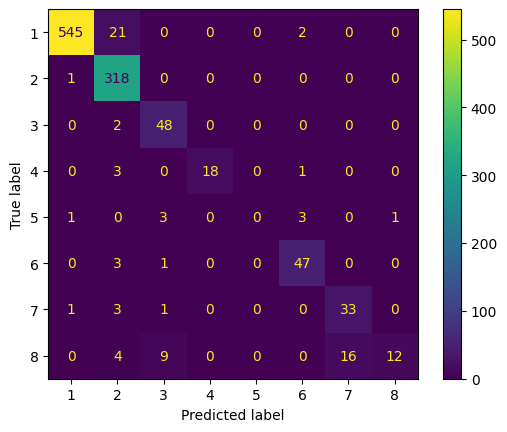

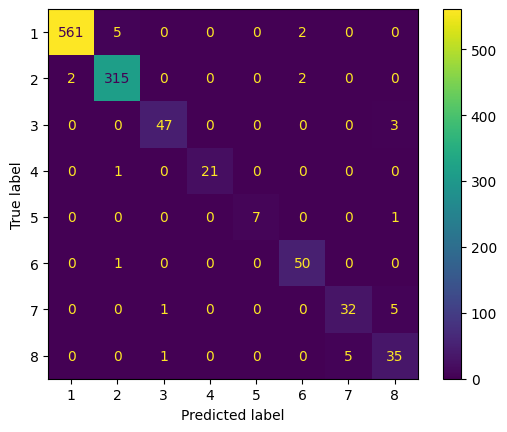

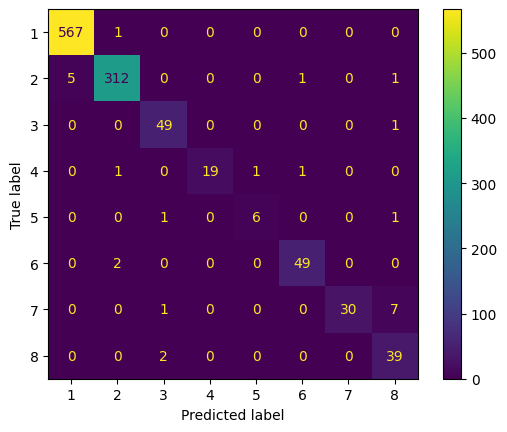

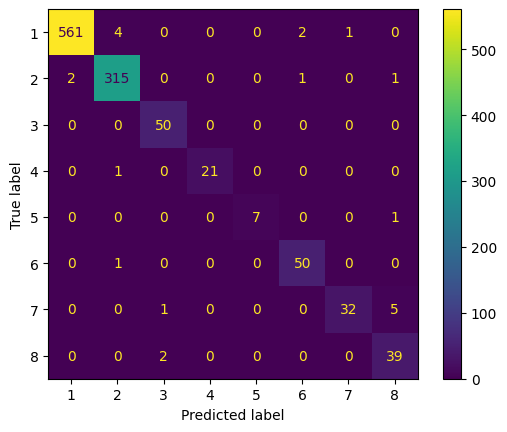

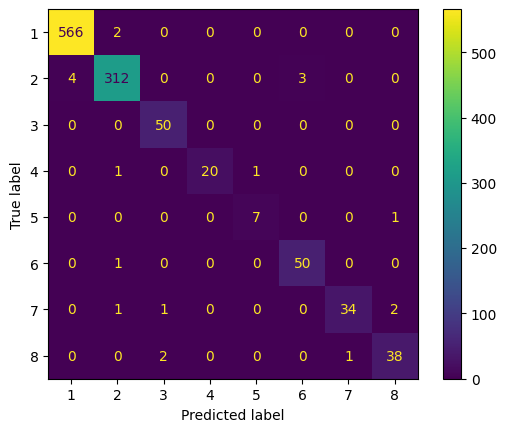

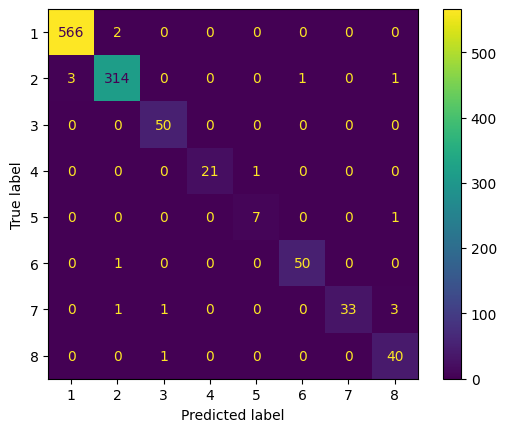

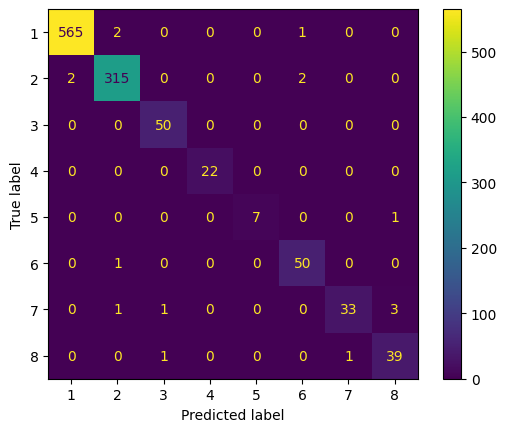

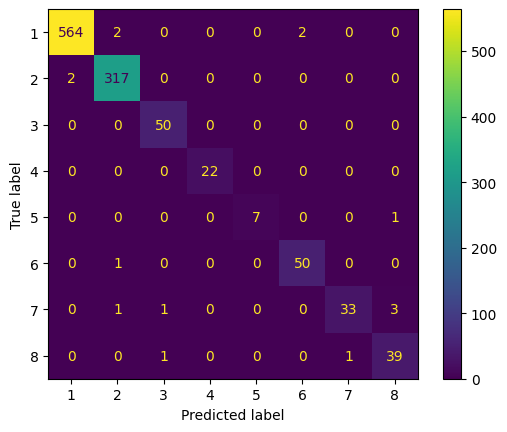

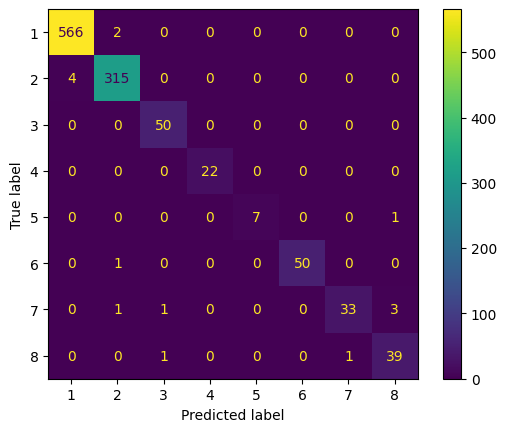

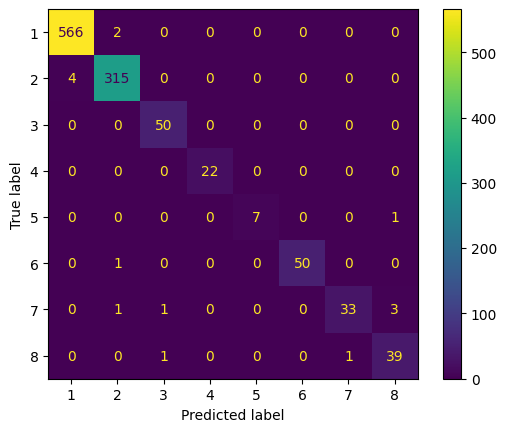

TrainOutput(global_step=1380, training_loss=0.11391903386599776, metrics={'train_runtime': 208.0245, 'train_samples_per_second': 210.937, 'train_steps_per_second': 6.634, 'total_flos': 307442692022400.0, 'train_loss': 0.11391903386599776, 'epoch': 10.0})

In [33]:
# Model, training args and trainer

from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
import torch

device = torch.device('cuda'if torch.cuda.is_available() else 'cpu')

# place the model on the GPU is available
#model = AutoModelForSequenceClassification.from_pretrained(
 #   "distilbert/distilbert-base-uncased", num_labels=8, id2label=id2label, label2id=label2id
#).to(device)
#model = AutoModelForSequenceClassification.from_pretrained(
 #   "google/bert_uncased_L-2_H-128_A-2", num_labels=8, id2label=id2label, label2id=label2id
#).to(device)
model = AutoModelForSequenceClassification.from_pretrained(
    "google/bert_uncased_L-4_H-256_A-4", num_labels=8, id2label=id2label, label2id=label2id
).to(device)


training_args = TrainingArguments(
    output_dir="document_classification",
    learning_rate=1e-4,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=10,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_hf_dataset['train'],
    eval_dataset=tokenized_hf_dataset['test'],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

"To do" left is hyperparameter tuning. However, since the accuracy is already at 98% (which is higher than other Kaggle competitors), and precision and recall are over 0.94, we can skip this part since it would only yield marginal improvements.

## Explainability using SHAP <a name="shap"></a>

In [41]:
import shap
import scipy as sp

# define a prediction function
def f(x):
    tv = torch.tensor([tokenizer.encode(v, padding="max_length", max_length=512, truncation=True) for v in x]).to(device)
    outputs = model(tv)[0].detach().cpu().numpy()
    scores = (np.exp(outputs).T / np.exp(outputs).sum(-1)).T
    val = sp.special.logit(scores[:, 1])  # use one vs rest logit units
    return val


explainer = shap.Explainer(f, tokenizer)
shap_values = explainer(hf_dataset['train']['document'][:10], fixed_context=1)

# plot shap_values for the 3rd document
shap.plots.text(shap_values[3])

When we pass a single instance to the text plot we get the importance of each token overlayed on the original text that corresponds to that token. Red regions correspond to parts of the text that increase the output of the model when they are included, while blue regions decrease the output of the model when they are included. In the context of the document classification model here red corresponds to a predicted category and blue to other categories.

Specifically, the shown document is in the class 1. Therefore, the red tokens were the most important to choose the class 1.

## Inference <a name="inference"></a>

In [31]:
from transformers import pipeline

# substring of the first document (class 1)
text = "champion products inc said its board of directors approved a two for one stock split of its common shares for shareholders of record as of april"

classifier = pipeline("text-classification", model=f"{cwd}/document_classification/checkpoint-1360")
prediction = classifier(text)
print(f"Predicted class: {prediction[0]['label']}")

Hardware accelerator e.g. GPU is available in the environment, but no `device` argument is passed to the `Pipeline` object. Model will be on CPU.


Predicted class: 1


# Conclusion <a name="conclusion"></a>

Since BERT-Mini has the best performance of all of the tried models, and there was no need to do over- and undersampling, let's use this model for the production.